# 02 — Land, river, and sea-ice initial conditions for RTENSO2026: year selection

No model restarts exist for 2026, so the ELM (land), MOSART (river), and
MPAS-Seaice initial conditions come from one year of the BruteForce archive,
used unchanged (averaging restarts would break the consistency of snow layers,
ice categories, and phenology). Two branches choose the year:

| Branch | Year selected | Target |
| --- | --- | --- |
| `clim` | closest to the climatology | candidate-year mean |
| `obs` | closest to the observed state | observed anomaly on the target date (ERA5) |
| `obs_era5land_nsidc` | closest to the observed state | observed anomaly on the target date (ERA5-Land land, NOAA/NSIDC CDR sea ice) |

`obs_era5land_nsidc` is the default observation set: the 1-degree ERA5-Land
(`sd`, `swvl1`, `swvl2-4`, `stl1`) for land and the NOAA/NSIDC sea-ice
concentration CDR (G02202 v6, daily) for sea ice. `obs` is the same selection
with ERA5 (0.25 degree) for both.
Each `obs*` branch is written to its own subdirectory.

The 2015 dates are done the same way, with 2015 excluded from the candidates,
to test hindcast sensitivity against the actual 2015 restarts. Similarity checks
and spatial plots comparing the `clim` and `obs` choices against the actual 2015
restarts are in `04_evaluate_ic_metrics.ipynb`, `05_plot_mpassi_ic_mosaic.ipynb`, and `06_plot_elm_ic_mosaic.ipynb`.
The box size `BOX` comes from `01_choose_box_size.ipynb`; the climatology-plus-anomaly
option built on the `clim` year is `03_build_clim_anomaly_ic.ipynb`.

## Distance metric

For key field $f$ (section 1), candidate-year values are converted to
standardized anomalies $z_{y,i}=(x_{y,i}-\bar x_i)/S$, where
$S^2=\sum_i w_i s_i^2/\sum_i w_i$ is the area-weighted mean interannual
variance over the candidate years. The distance of year $y$ from a target
$t$ is

$$d_f(y)=\sqrt{\frac{\sum_i w_i\,(z_{y,i}-t_i)^2}{\sum_i w_i}}$$

- `clim`: $t=0$. $d_f$ is the RMS anomaly relative to the RMS spread; its mean
  square over the candidate years is 1, so $d_f<1$ is closer than a typical year.
- `obs`: $t$ is the ERA5 standardized anomaly on the target date,
  $(o_T-\bar o)/S_\mathrm{obs}$, with the ERA5 mean and spread over the same
  candidate years and date. Comparing anomalies cancels model-ERA5 biases and
  unit or layer-depth differences. Only fields with an ERA5 counterpart are
  used.

The river (MOSART) is not in the distance (its storage is driven by land
runoff); its restart always comes from the land year. The two soil-water
fields cover disjoint layers (1-3 and 4+), so no layer is counted twice.

Component distance $D_c=\sqrt{\operatorname{mean}_{f\in c} d_f^2}$; joint
distance $D=\sqrt{\sum_c a_c D_c^2/\sum_c a_c}$ with component weights $a_c$
(default 1). `MODE = "joint"` takes the year with the smallest $D$ for all
components (one coupled state); `"per_component"` takes each component's
smallest $D_c$.

The BruteForce archive is read-only here. Code: `util/clim_restart.py`.

For the 2015 sensitivity check and native-grid spatial similarity comparisons against the actual 2015 restarts, see:
- `04_evaluate_ic_metrics.ipynb` — Distance/rank checks, field-level similarity tables (`d_box`, `r_box`, `d_grid`, `r_grid`, `RMSE`, `bias`), global integrated summaries, and `BOX`-scale anomaly maps
- `05_plot_mpassi_ic_mosaic.ipynb` — MPAS-Seaice native unstructured mesh comparisons via `mosaic`
- `06_plot_elm_ic_mosaic.ipynb` — ELM native `grid1d` land mesh comparisons via `mosaic`

In [1]:
from pathlib import Path
import importlib
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import netCDF4 as nc

SEARCH_ROOTS = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
HELPER_RELATIVE_PATHS = (
    Path("util"),
    Path("rtenso2026/util"),
    Path("ensemble_init/rtenso2026/util"),
    Path("e3sm_s2d_proc/ensemble_init/rtenso2026/util"),
)
HELPER_DIR = next(
    (
        root / relative_path
        for root in SEARCH_ROOTS
        for relative_path in HELPER_RELATIVE_PATHS
        if (root / relative_path / "clim_restart.py").is_file()
    ),
    None,
)
if HELPER_DIR is None:
    raise FileNotFoundError("Could not find util/clim_restart.py from the notebook directory.")
if str(HELPER_DIR) not in sys.path:
    sys.path.insert(0, str(HELPER_DIR))

import clim_restart
clim_restart = importlib.reload(clim_restart)
from clim_restart import (
    compute_distances,
    distance_to_model_year,
    era5_available,
    make_plan,
    metric_table,
    select_years,
    source_file,
    summarize_restart,
    write_selected_restarts,
)

warnings.filterwarnings("ignore", category=RuntimeWarning)

## Configuration

In [2]:
# Model initial-condition archive (BruteForce restarts, opened read-only).
SRC_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/v3.LR.S2D.ENSINT/BruteForce")
SRC_PREFIX = "20251024_s2d_spinup"

# Observation sets for the obs branches: per-component root and observed fields
# (ERA5 names; a root of None falls back to the NERSC ERA5 archive). The data
# format (ERA5 0.25 deg, ERA5-Land 1x1, or NOAA/NSIDC 1x1) is recognized from
# the root layout. Each set is written to OUT_ROOT/YYYYMMDD/<set name>.
ERA5_DIR = Path("/global/cfs/projectdirs/m3522/cmip6/ERA5/e5.oper.an.sfc")
OBS_DATA = Path("/global/cfs/cdirs/e3sm/zhan391/data")
OBS_SETS = {
    # ERA5 for land and sea ice.
    "obs": {
        "root": {"elm": ERA5_DIR, "mpassi": ERA5_DIR},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
    # Default: ERA5-Land for land, NOAA/NSIDC sea-ice concentration CDR for sea ice.
    "obs_era5land_nsidc": {
        "root": {"elm": OBS_DATA / "ERA5_LND", "mpassi": OBS_DATA / "NOAA_NSIDC"},
        "fields": {"elm": ["sd", "swvl1", "swvl2-4", "stl1", "stl2-4"], "mpassi": ["ci"]},
    },
}

# Fixed RTENSO2026 output location: OUT_ROOT/YYYYMMDD/<branch>/<prefix>.<stream>.<date>.nc
OUT_ROOT = Path("/global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions")

OUT_PREFIX = "20251024_s2d_spinup"   # matches my_refcase2 in the hindcast driver

BRANCHES = ["clim", "obs", "obs_era5land_nsidc"]   # "obs_era5land_nsidc" = ERA5-Land + NSIDC (default); "obs" = ERA5

COMPONENTS = ["elm", "mosart", "mpassi"]

TEST_DATES = ["2015-02-01", "2015-05-01", "2015-08-01", "2015-11-01"]

HINDCAST_DATES = ["2026-02-01", "2026-05-01", "2026-08-01", "2026-11-01"]

TARGET_DATES = TEST_DATES + HINDCAST_DATES

# Candidate years. None uses every available year (1980-2018). Recent years only: the
# restart is used unchanged, so its place on the trend is part of the state it brings
# (1995-2018 matched the actual 2015 state best; see 04).
FIRST_YEAR = 1995  # None is 1980
LAST_YEAR = None  # None is 2018

EXCLUDE_YEARS = []
EXCLUDE_TARGET_YEAR = True          # 2015 cannot select itself

# Compare area-weighted means over (dlat, dlon)-degree boxes; None = model points.
# 15 x 30 from the leave-one-out test in 01_choose_box_size.ipynb (README, "Choice of box size").
BOX = (15, 30)
# Placements of the box edges averaged in the distance (1, 2, or 4), from 01_choose_box_size.ipynb.
BOX_SHIFTS = 4

# modes: use joint for all components or per_component for individual components
MODE = "joint"  # or "per_component"

# weight for components 
# e.g. {"mpassi": 2.0}; default 1 each 
COMPONENT_WEIGHTS = {
    "mpassi": 1.0,
    "elm": 1.0
}

# Model and observation key fields are cached under the output root.
CACHE_DIR = OUT_ROOT / "cache"

WRITE_OUTPUT = True                 # True copies the selected restarts to OUT_ROOT
OVERWRITE = True                    # replace restarts whose selected year changed

## 1. Key fields and their observed counterparts

In [3]:
for name in [b for b in BRANCHES if b in OBS_SETS]:
    print(name)
    display(metric_table(OBS_SETS[name]["fields"]))

obs


,component,field,model definition,"domain, weight",ERA5 (obs branch)
0,mpassi,NH ice concentration,sum of iceAreaCategory,"lat > 0, areaCell",ci
1,mpassi,SH ice concentration,sum of iceAreaCategory,"lat < 0, areaCell",ci
2,mpassi,NH ice thickness,sum of iceVolumeCategory (m),"lat > 0, areaCell",--
3,mpassi,SH ice thickness,sum of iceVolumeCategory (m),"lat < 0, areaCell",--
4,mpassi,NH snow on ice,sum of snowVolumeCategory (m),"lat > 0, areaCell",--
5,mpassi,SH snow on ice,sum of snowVolumeCategory (m),"lat < 0, areaCell",--
6,elm,snow water equivalent,H2OSNO (mm),"active columns, cols1d_wtxy*cos(lat)",sd
7,elm,surface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 1-3 (kg m-2)","active columns, cols1d_wtxy*cos(lat)",swvl1
8,elm,subsurface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 4 and bel...","active columns, cols1d_wtxy*cos(lat)",swvl2-4
9,elm,surface soil temperature,"T_SOISNO, soil layer 1 (K)","active columns, cols1d_wtxy*cos(lat)",stl1


obs_era5land_nsidc


,component,field,model definition,"domain, weight",ERA5 (obs branch)
0,mpassi,NH ice concentration,sum of iceAreaCategory,"lat > 0, areaCell",ci
1,mpassi,SH ice concentration,sum of iceAreaCategory,"lat < 0, areaCell",ci
2,mpassi,NH ice thickness,sum of iceVolumeCategory (m),"lat > 0, areaCell",--
3,mpassi,SH ice thickness,sum of iceVolumeCategory (m),"lat < 0, areaCell",--
4,mpassi,NH snow on ice,sum of snowVolumeCategory (m),"lat > 0, areaCell",--
5,mpassi,SH snow on ice,sum of snowVolumeCategory (m),"lat < 0, areaCell",--
6,elm,snow water equivalent,H2OSNO (mm),"active columns, cols1d_wtxy*cos(lat)",sd
7,elm,surface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 1-3 (kg m-2)","active columns, cols1d_wtxy*cos(lat)",swvl1
8,elm,subsurface soil water,"H2OSOI_LIQ + H2OSOI_ICE, soil layers 4 and bel...","active columns, cols1d_wtxy*cos(lat)",swvl2-4
9,elm,surface soil temperature,"T_SOISNO, soil layer 1 (K)","active columns, cols1d_wtxy*cos(lat)",stl1


## 2. Distances and selection

The first run for a calendar month reads the model key fields (about 3.5
minutes) and, for each `obs*` branch, the observed fields (one 00Z slice per variable and year);
both are cached. An `obs*` branch is skipped for dates its observations do not cover yet.

In [4]:
plans = {}
distances = {}
selections = {}

for branch in BRANCHES:
    kind = "clim" if branch == "clim" else "obs"
    obs_set = OBS_SETS.get(branch, {})
    obs_root, obs_fields = obs_set.get("root"), obs_set.get("fields")
    for date in TARGET_DATES:
        if kind == "obs" and not era5_available(
            date, obs_root=obs_root, obs_fields=obs_fields, components=COMPONENTS
        ):
            print(f"skip {branch} {date}: observations not available yet")
            continue
        plan = make_plan(
            date, kind, components=COMPONENTS,
            src_root=SRC_ROOT, src_prefix=SRC_PREFIX,
            out_root=OUT_ROOT, out_prefix=OUT_PREFIX,
            obs_root=obs_root, obs_fields=obs_fields,
            first_year=FIRST_YEAR, last_year=LAST_YEAR,
            exclude_years=EXCLUDE_YEARS, exclude_target_year=EXCLUDE_TARGET_YEAR,
            label=branch,
        )
        table = compute_distances(plan, box=BOX, box_shifts=BOX_SHIFTS, component_weights=COMPONENT_WEIGHTS,
                                  cache_dir=CACHE_DIR)
        key = (branch, date)
        plans[key], distances[key] = plan, table
        selections[key] = select_years(table, COMPONENTS, MODE)

summary = []
for (branch, date), table in distances.items():
    ranked = table["joint"].sort_values()
    row = {"branch": branch, "target_date": date, "n_candidates": len(table)}
    row.update({f"{c} year": y for c, y in selections[(branch, date)].items()})
    row.update({"best D": ranked.iloc[0], "2nd year": ranked.index[1], "2nd D": ranked.iloc[1],
                "3rd year": ranked.index[2], "3rd D": ranked.iloc[2]})
    summary.append(row)
summary = pd.DataFrame(summary)
display(summary.round(3))

skip obs 2026-08-01: observations not available yet
skip obs 2026-11-01: observations not available yet


skip obs_era5land_nsidc 2026-11-01: observations not available yet


,branch,target_date,n_candidates,elm year,mosart year,mpassi year,best D,2nd year,2nd D,3rd year,3rd D
0,clim,2015-02-01,23,2010,2010,2010,0.838,2004,0.879,2000,0.879
1,clim,2015-05-01,23,2004,2004,2004,0.843,2009,0.853,2002,0.882
2,clim,2015-08-01,23,2009,2009,2009,0.798,2008,0.833,2006,0.928
3,clim,2015-11-01,23,2008,2008,2008,0.866,1995,0.872,1999,0.873
4,clim,2026-02-01,24,2010,2010,2010,0.839,2009,0.876,2004,0.877
5,clim,2026-05-01,24,2009,2009,2009,0.840,2004,0.843,2007,0.882
6,clim,2026-08-01,24,2009,2009,2009,0.786,2008,0.823,1997,0.926
7,clim,2026-11-01,24,1995,1995,1995,0.869,2008,0.871,1999,0.885
8,obs,2015-02-01,23,2014,2014,2014,1.323,2010,1.360,2004,1.366
9,obs,2015-05-01,23,2014,2014,2014,1.245,2008,1.306,2012,1.321


In [5]:
# Ten closest years for each branch and date (field, component, and joint distances).
for (branch, date), table in distances.items():
    print(f"{branch} {date}")
    display(table.sort_values("joint").head(10).round(3))

clim 2015-02-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm: subsurface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi: NH ice thickness,mpassi: SH ice thickness,mpassi: NH snow on ice,mpassi: SH snow on ice,mpassi,joint
year,,,,,,,,,,,,,,
2010,0.863,0.940,0.819,1.020,1.054,0.944,0.676,0.827,0.459,0.822,0.756,0.689,0.716,0.838
2004,0.850,0.988,1.052,0.650,0.638,0.853,1.069,0.822,0.968,0.821,0.962,0.746,0.905,0.879
2000,0.788,0.838,0.799,0.913,0.986,0.868,0.733,1.062,1.091,0.827,0.641,0.900,0.891,0.879
2009,0.772,0.997,0.999,0.892,0.844,0.905,0.902,0.941,0.667,0.775,0.753,1.102,0.868,0.887
2007,1.165,0.814,0.791,1.035,0.838,0.940,0.588,0.732,0.638,0.738,0.973,1.176,0.833,0.888
2005,0.953,0.977,0.907,1.087,0.787,0.947,0.764,0.888,0.885,1.211,1.139,0.567,0.935,0.941
2002,0.725,0.761,0.805,0.981,0.849,0.829,0.811,1.024,1.063,1.203,1.042,1.184,1.062,0.953
1996,1.107,0.939,1.113,1.059,1.022,1.050,1.180,0.773,0.937,0.705,0.867,0.648,0.870,0.964
1995,1.021,1.007,1.168,0.845,1.152,1.045,1.016,0.606,0.814,0.606,1.318,0.735,0.886,0.969


clim 2015-05-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm: subsurface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi: NH ice thickness,mpassi: SH ice thickness,mpassi: NH snow on ice,mpassi: SH snow on ice,mpassi,joint
year,,,,,,,,,,,,,,
2004,1.050,1.031,0.751,0.982,0.692,0.914,0.790,0.716,0.678,0.598,1.013,0.732,0.766,0.843
2009,0.706,1.065,1.093,0.646,0.738,0.871,0.694,0.942,0.590,0.812,0.758,1.112,0.835,0.853
2002,0.870,0.840,0.722,0.951,0.901,0.860,0.630,1.075,0.845,0.966,0.984,0.853,0.903,0.882
2007,0.782,0.966,0.705,1.155,0.742,0.886,0.785,0.972,0.734,0.826,0.997,0.964,0.886,0.886
2000,0.721,0.830,1.244,1.092,1.071,1.010,0.616,0.991,0.934,0.739,0.576,0.776,0.787,0.905
1996,1.097,0.821,0.972,0.937,1.209,1.016,0.902,0.791,0.905,0.758,0.799,0.723,0.816,0.921
2012,0.923,0.841,0.927,0.879,0.949,0.905,0.907,1.053,0.966,0.739,1.112,0.904,0.954,0.930
1995,1.176,1.094,0.943,1.110,1.124,1.092,0.940,0.646,0.686,0.466,1.073,0.431,0.744,0.935
2011,0.887,1.063,1.186,0.869,0.931,0.994,0.928,0.930,0.798,1.129,0.732,0.967,0.923,0.959


clim 2015-08-01


...

,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm: subsurface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,,
2010,1.457,1.283,1.840,1.172,1.920,1.563,0.898,0.978,0.939,1.289
2013,1.488,1.223,1.799,1.299,1.619,1.500,1.011,1.187,1.102,1.316
2015,1.354,1.181,1.591,1.080,1.951,1.465,1.459,1.344,1.402,1.434
2014,1.452,1.365,1.712,1.424,1.915,1.587,1.481,1.044,1.281,1.442
2006,1.360,1.308,1.917,1.576,1.958,1.647,0.998,1.393,1.211,1.445
2018,1.415,1.316,1.955,1.750,1.979,1.705,1.067,1.227,1.150,1.454
2009,1.301,1.246,1.694,1.246,1.943,1.513,1.300,1.562,1.437,1.475
2007,1.596,1.176,1.898,1.132,1.939,1.586,1.237,1.520,1.385,1.489
2011,1.253,1.214,1.667,1.283,1.821,1.469,1.193,1.780,1.515,1.492


obs_era5land_nsidc 2026-05-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm: subsurface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,,
2011,1.177,1.253,1.602,1.251,1.777,1.432,1.139,1.046,1.094,1.274
2007,1.233,1.444,1.610,1.269,1.583,1.436,1.147,1.153,1.150,1.301
2006,1.195,1.500,1.694,1.498,1.698,1.528,1.268,0.876,1.090,1.327
2002,1.215,1.263,1.549,1.323,2.112,1.528,1.321,0.997,1.170,1.361
2013,1.394,1.636,1.640,1.541,1.825,1.613,1.042,1.102,1.072,1.370
2018,1.523,1.389,1.742,1.204,1.720,1.529,1.419,0.968,1.215,1.381
2016,1.815,1.700,1.913,1.390,1.539,1.682,0.790,1.453,1.170,1.449
2009,1.313,1.495,1.705,1.221,1.964,1.563,1.505,1.162,1.344,1.458
2012,1.388,1.436,1.592,1.485,1.602,1.503,1.326,1.509,1.420,1.462


obs_era5land_nsidc 2026-08-01


,elm: snow water equivalent,elm: surface soil water,elm: subsurface soil water,elm: surface soil temperature,elm: subsurface soil temperature,elm,mpassi: NH ice concentration,mpassi: SH ice concentration,mpassi,joint
year,,,,,,,,,,
2016,1.384,1.539,1.949,1.509,1.522,1.592,1.205,0.813,1.028,1.340
2005,1.517,1.387,2.034,1.434,1.904,1.676,0.733,1.213,1.002,1.381
2013,1.325,1.378,1.724,1.537,2.084,1.633,0.886,1.424,1.186,1.427
2006,1.299,1.329,1.622,2.044,1.985,1.685,0.745,1.408,1.127,1.434
2009,1.299,1.391,1.806,1.926,2.247,1.769,0.963,1.172,1.073,1.463
2018,1.533,1.385,1.823,2.049,1.977,1.772,0.919,1.269,1.108,1.478
2012,1.899,1.389,1.738,1.427,1.890,1.683,1.441,1.042,1.258,1.486
2015,1.610,1.708,1.879,1.530,1.922,1.736,1.257,1.117,1.189,1.488
2011,1.237,1.402,1.736,1.959,2.017,1.698,1.231,1.342,1.288,1.507


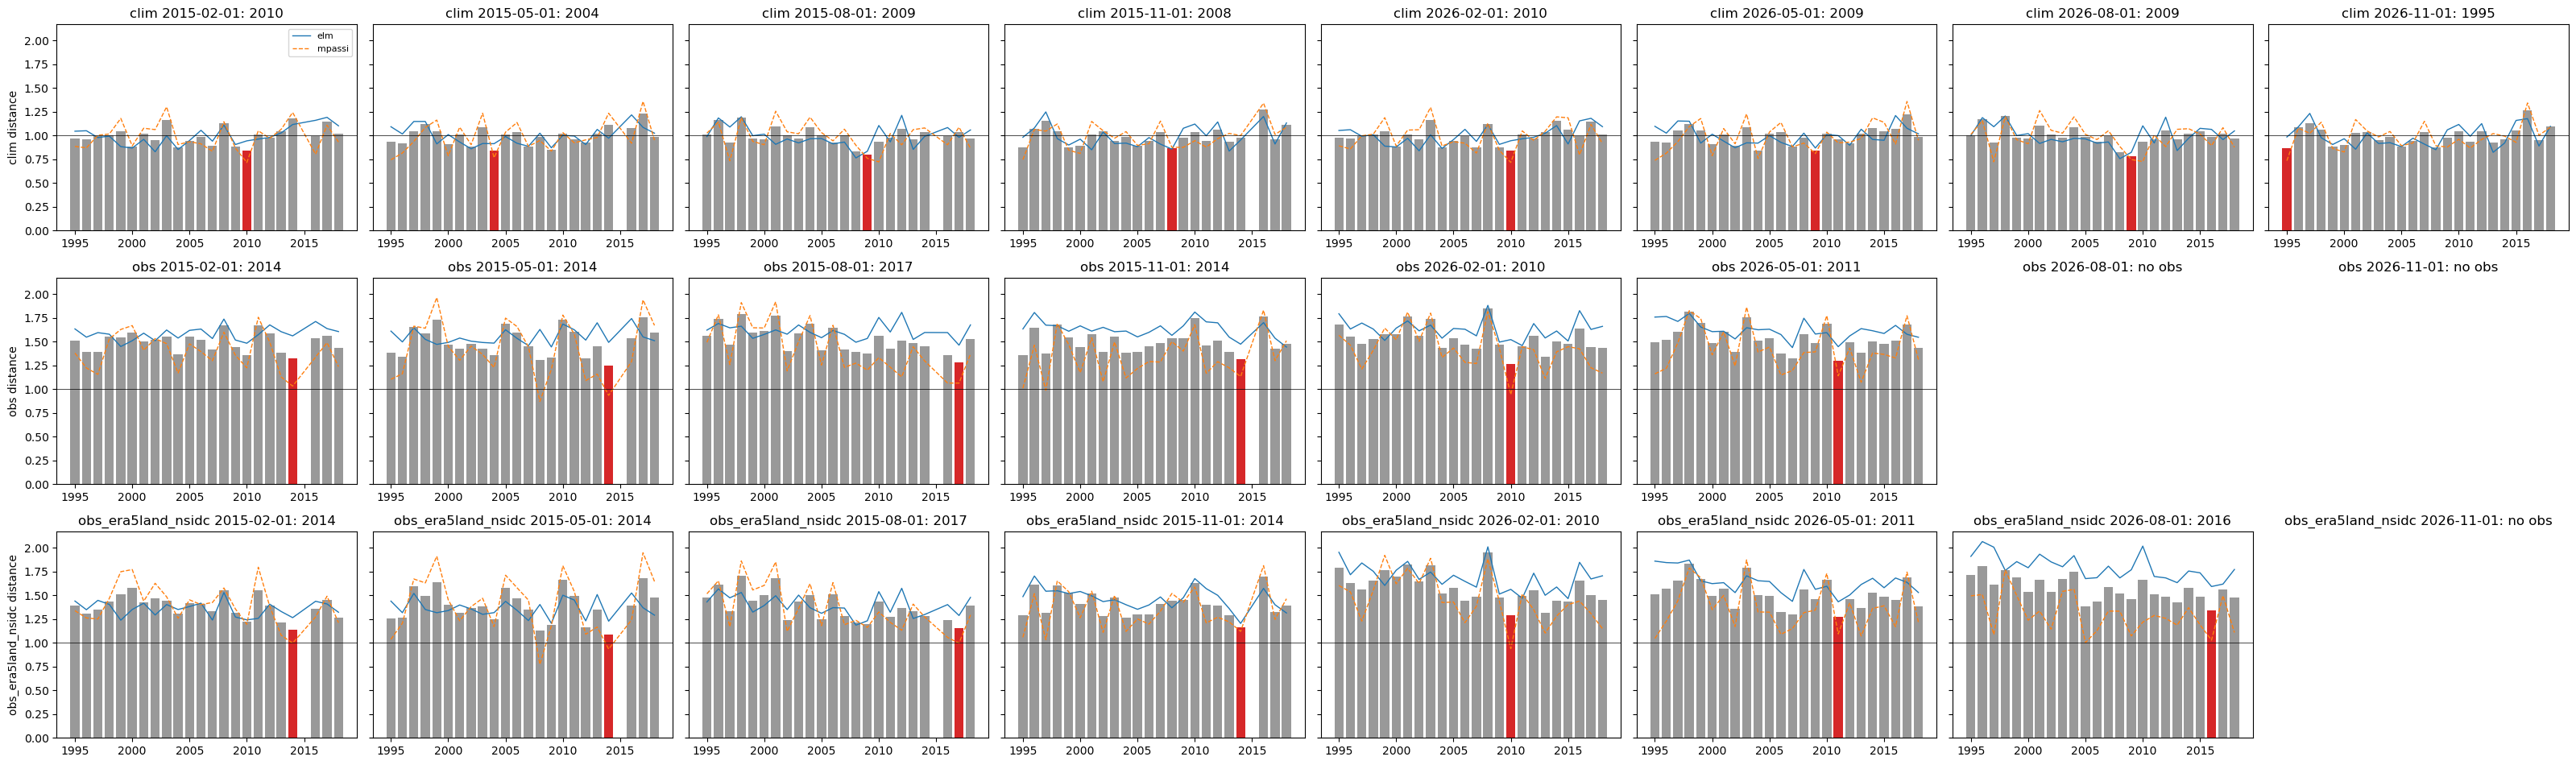

In [6]:
# Joint distance by year for each branch; the selected year is red.
fig, axes = plt.subplots(len(BRANCHES), len(TARGET_DATES), figsize=(4 * len(TARGET_DATES), 3.2 * len(BRANCHES)),
                         sharey=True, squeeze=False)
for r, branch in enumerate(BRANCHES):
    for c, date in enumerate(TARGET_DATES):
        ax = axes[r, c]
        if (branch, date) not in distances:
            ax.set_title(f"{branch} {date}: no obs")
            ax.axis("off")
            continue
        table = distances[(branch, date)]
        best = int(table["joint"].idxmin())
        years = table.index.to_numpy()
        ax.bar(years, table["joint"], color=["tab:red" if y == best else "0.6" for y in years])
        for comp, style in zip([c for c in COMPONENTS if c in table], ("-", "--", ":")):
            ax.plot(years, table[comp], style, lw=1, label=comp)
        ax.axhline(1, color="k", lw=0.5)
        ax.set_title(f"{branch} {date}: {best}")
    axes[r, 0].set_ylabel(f"{branch} distance")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
plt.show()

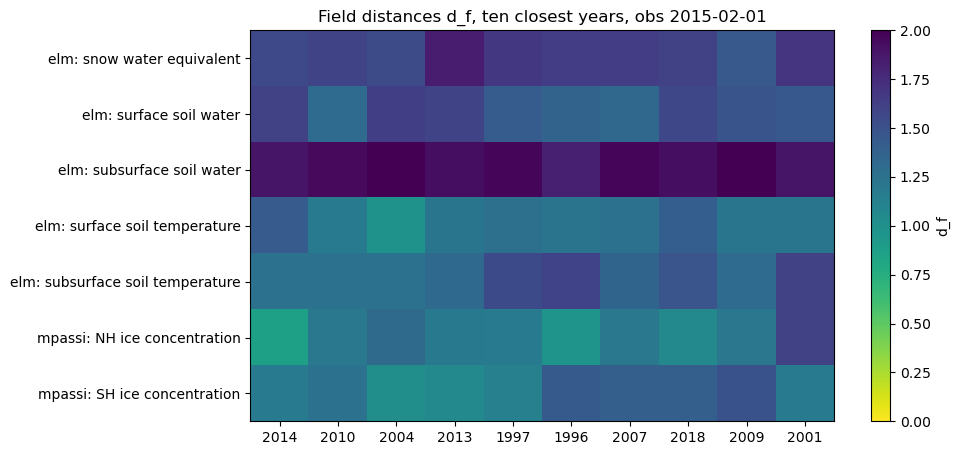

In [7]:
# Field distances of the ten closest years for one branch and date.
KEY = ("obs", TARGET_DATES[0])
table = distances[KEY].sort_values("joint").head(10)
fields = [c for c in table.columns if ": " in c]
fig, ax = plt.subplots(figsize=(10, 0.45 * len(fields) + 1.5))
im = ax.imshow(table[fields].T, aspect="auto", cmap="viridis_r", vmin=0, vmax=2)
ax.set_xticks(range(len(table)), table.index)
ax.set_yticks(range(len(fields)), fields)
ax.set_title(f"Field distances d_f, ten closest years, {KEY[0]} {KEY[1]}")
fig.colorbar(im, ax=ax, label="d_f")
fig.tight_layout()
plt.show()

## 3. Write the selected restarts

Copies each selected restart (unchanged) to
`OUT_ROOT/YYYYMMDD/<branch>/<prefix>.<stream>.<target date>.nc` (one directory per
branch, including each observation set), writes
`rpointer.lnd`, `rpointer.rof`, and `rpointer.ice`, and records the selection
and full distance table in `selection.json`. Set `WRITE_OUTPUT = True` to run.

In [8]:
if WRITE_OUTPUT:
    for key, plan in plans.items():
        write_selected_restarts(plan, selections[key], distances[key], mode=MODE, box=BOX, box_shifts=BOX_SHIFTS,
                                component_weights=COMPONENT_WEIGHTS, overwrite=OVERWRITE)

rows = []
for (branch, date), plan in plans.items():
    for comp in COMPONENTS:
        year = selections[(branch, date)][comp]
        out, src = plan.output(comp), plan.source(comp, year)
        rows.append({"branch": branch, "target_date": date, "component": comp, "year": year,
                     "written": out.is_file(),
                     "same size as source": out.is_file() and out.stat().st_size == src.stat().st_size})
display(pd.DataFrame(rows))

  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/clim/20251024_s2d_spinup.elm.r.2015-02-01-00000.nc already holds 2010; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/clim/20251024_s2d_spinup.mosart.r.2015-02-01-00000.nc already holds 2010; not copied
  mpassi: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150201/clim/20251024_s2d_spinup.mpassi.rst.2015-02-01_00000.nc already holds 2010; not copied


  elm: 20251024_s2d_spinup.elm.r.2004-05-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150501/clim/20251024_s2d_spinup.elm.r.2015-05-01-00000.nc (56 s)


  mosart: 20251024_s2d_spinup.mosart.r.2004-05-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150501/clim/20251024_s2d_spinup.mosart.r.2015-05-01-00000.nc (0 s)


  mpassi: 20251024_s2d_spinup.mpassi.rst.2004-05-01_00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150501/clim/20251024_s2d_spinup.mpassi.rst.2015-05-01_00000.nc (5 s)
  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/clim/20251024_s2d_spinup.elm.r.2015-08-01-00000.nc already holds 2009; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/clim/20251024_s2d_spinup.mosart.r.2015-08-01-00000.nc already holds 2009; not copied
  mpassi: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/clim/20251024_s2d_spinup.mpassi.rst.2015-08-01_00000.nc already holds 2009; not copied
  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20151101/clim/20251024_s2d_spinup.elm.r.2015-11-01-00000.nc already holds 2008; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20151101/clim/20251024_s2d_spinup.mosart.r.2015-11-01-00000.nc already holds 2008; not copied
 

  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/clim/20251024_s2d_spinup.elm.r.2026-08-01-00000.nc already holds 2009; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/clim/20251024_s2d_spinup.mosart.r.2026-08-01-00000.nc already holds 2009; not copied
  mpassi: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/clim/20251024_s2d_spinup.mpassi.rst.2026-08-01_00000.nc already holds 2009; not copied


...

  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/obs_era5land_nsidc/20251024_s2d_spinup.elm.r.2015-08-01-00000.nc already holds 2017; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/obs_era5land_nsidc/20251024_s2d_spinup.mosart.r.2015-08-01-00000.nc already holds 2017; not copied
  mpassi: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20150801/obs_era5land_nsidc/20251024_s2d_spinup.mpassi.rst.2015-08-01_00000.nc already holds 2017; not copied
  elm: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20151101/obs_era5land_nsidc/20251024_s2d_spinup.elm.r.2015-11-01-00000.nc already holds 2014; not copied
  mosart: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20151101/obs_era5land_nsidc/20251024_s2d_spinup.mosart.r.2015-11-01-00000.nc already holds 2014; not copied
  mpassi: /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20151101/obs_era5land_nsidc/20251024_s2d_spinup.mpassi.r

  elm: 20251024_s2d_spinup.elm.r.2016-08-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/obs_era5land_nsidc/20251024_s2d_spinup.elm.r.2026-08-01-00000.nc (84 s)


  mosart: 20251024_s2d_spinup.mosart.r.2016-08-01-00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/obs_era5land_nsidc/20251024_s2d_spinup.mosart.r.2026-08-01-00000.nc (0 s)


  mpassi: 20251024_s2d_spinup.mpassi.rst.2016-08-01_00000.nc -> /global/cfs/cdirs/e3sm/S2S2D/RTENSO2026/initial_conditions/20260801/obs_era5land_nsidc/20251024_s2d_spinup.mpassi.rst.2026-08-01_00000.nc (9 s)


,branch,target_date,component,year,written,same size as source
0,clim,2015-02-01,elm,2010,True,True
1,clim,2015-02-01,mosart,2010,True,True
2,clim,2015-02-01,mpassi,2010,True,True
3,clim,2015-05-01,elm,2004,True,True
4,clim,2015-05-01,mosart,2004,True,True
...,...,...,...,...,...,...
58,obs_era5land_nsidc,2026-05-01,mosart,2011,True,True
59,obs_era5land_nsidc,2026-05-01,mpassi,2011,True,True
60,obs_era5land_nsidc,2026-08-01,elm,2016,True,True
61,obs_era5land_nsidc,2026-08-01,mosart,2016,True,True


## 4. Key findings

**Table 3. Archive years selected for the land, river, and sea-ice initial conditions.** For each
initialization date, one year of the 1995-2018 BruteForce archive (target year excluded) is selected, and its
ELM, MOSART, and MPAS-Seaice restarts are used unchanged. Each cell gives the closest year (bold, selected) and
the second-closest year, each with its distance D from the target in parentheses. The target is the
candidate-year climatology for the climatology-matched search and the observed anomaly on the target date
(ERA5-Land for land, NOAA/NSIDC CDR for sea-ice concentration) for the observation-matched search. D is the
joint standardized RMS distance over the land key fields (snow water equivalent, surface and subsurface soil
water, surface and subsurface soil temperature) and the sea-ice key fields, computed on 15°x30° box means and
averaged over four placements of the box grid; lower is closer. For reference, the median D over all
candidate years is about 1.0 for the climatology-matched search and 1.4-1.6 for the observation-matched
search. Nearly equal D values for the two years indicate that both are about equally close. Using ERA5 for
both land and sea ice selects the same year on every date where ERA5 is available.

| Date | Climatology-matched: closest (D) / 2nd-closest (D) | Observation-matched: closest (D) / 2nd-closest (D) |
|---|---|---|
| 2015-02-01 | **2010** (0.84) / 2004 (0.88) | **2014** (1.14) / 2013 (1.21) |
| 2015-05-01 | **2004** (0.84) / 2009 (0.85) | **2014** (1.09) / 2008 (1.13) |
| 2015-08-01 | **2009** (0.80) / 2008 (0.83) | **2017** (1.15) / 2009 (1.20) |
| 2015-11-01 | **2008** (0.87) / 1995 (0.87) | **2014** (1.16) / 2004 (1.27) |
| 2026-02-01 | **2010** (0.84) / 2009 (0.88) | **2010** (1.29) / 2013 (1.32) |
| 2026-05-01 | **2009** (0.84) / 2004 (0.84) | **2011** (1.27) / 2007 (1.30) |
| 2026-08-01 | **2009** (0.79) / 2008 (0.82) | **2016** (1.34) / 2005 (1.38) |
| 2026-11-01 | **1995** (0.87) / 2008 (0.87) | observations not yet available |

1. **`clim` picks years near the climatology, often with a close 2nd.** The selected years (mostly 2008-2010;
   2004 for May 2015, 1995 for Nov 2026) are clearly closer to the climatology than a typical year (D =
   0.79-0.87 vs about 1.0), but the 2nd-closest year is often almost as close (May and Nov differ by 0.01 or
   less): several years are about equally near the mean state, so the choice among them is close to arbitrary.
2. **`obs` picks a year near the target, and the choice is better determined.** For 2015, 2014 is selected for
   three of four dates and 2017 for Aug. The 2nd-closest year is usually 0.03-0.11 farther.
3. **The best year matches the observed anomaly only partly.** Its D (1.09-1.34) is clearly below the typical
   1.4-1.6, but well above 0: no archive year reproduces the observed state closely. This motivates the
   climatology-plus-anomaly option (`03_build_clim_anomaly_ic.ipynb`).
4. **The selection does not depend on the observation dataset.** ERA5 and ERA5-Land/NSIDC pick the same year on
   every date where both are available. Distances are lower with ERA5-Land/NSIDC for the 2015 dates (1.09-1.16
   vs 1.25-1.32) and similar for 2026.
5. **One coupled state.** The joint mode gives one year for land, river, and sea ice on every date.
6. **For 2015, the `obs` year is the closest candidate to the actual 2015 state** (`04_evaluate_ic_metrics.ipynb`,
   scored on 15x30 boxes): rank 1 of 23 on all four dates for the observed fields (rank correlation 0.71-0.94
   between the observation-based and true distances), and rank 1, 1, 7, 1 for all key fields (in Aug, the
   unobserved sea-ice thickness and snow on ice favour 2009, D = 1.15 vs 1.31 for 2017).
7. **Adding subsurface soil temperature changed only three selections**, all previously near ties: `clim`
   2015-05 (2009 to 2004) and 2026-11 (2008 to 1995), and `obs` Aug 2026 (2005 to 2016).

These numbers come from the tables above; update this section if the configuration changes.